## MTL Trajet: 03 Purpose Time Distance Speed (Flag 3)

### Dataset Overview
MTL Trajet 2016 mobility data with trip purpose, mode, timing, endpoints, trip metrics, and Montréal PUM 2050 destination land-use categories. User IDs distinguish participants, and the point tables provide speed profiles. The single-user case includes a repeated work corridor.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze differences in trajectory dynamics, speed change, and trip structure across trip purposes in the supplied multiple-user trajectories.

Role: Urban mobility and land-use analyst


Category: Purpose-conditioned trajectory dynamics, point-wise speed variation, and trip structure

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do point-wise speed stability and stop/restart events differ across trip purposes?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

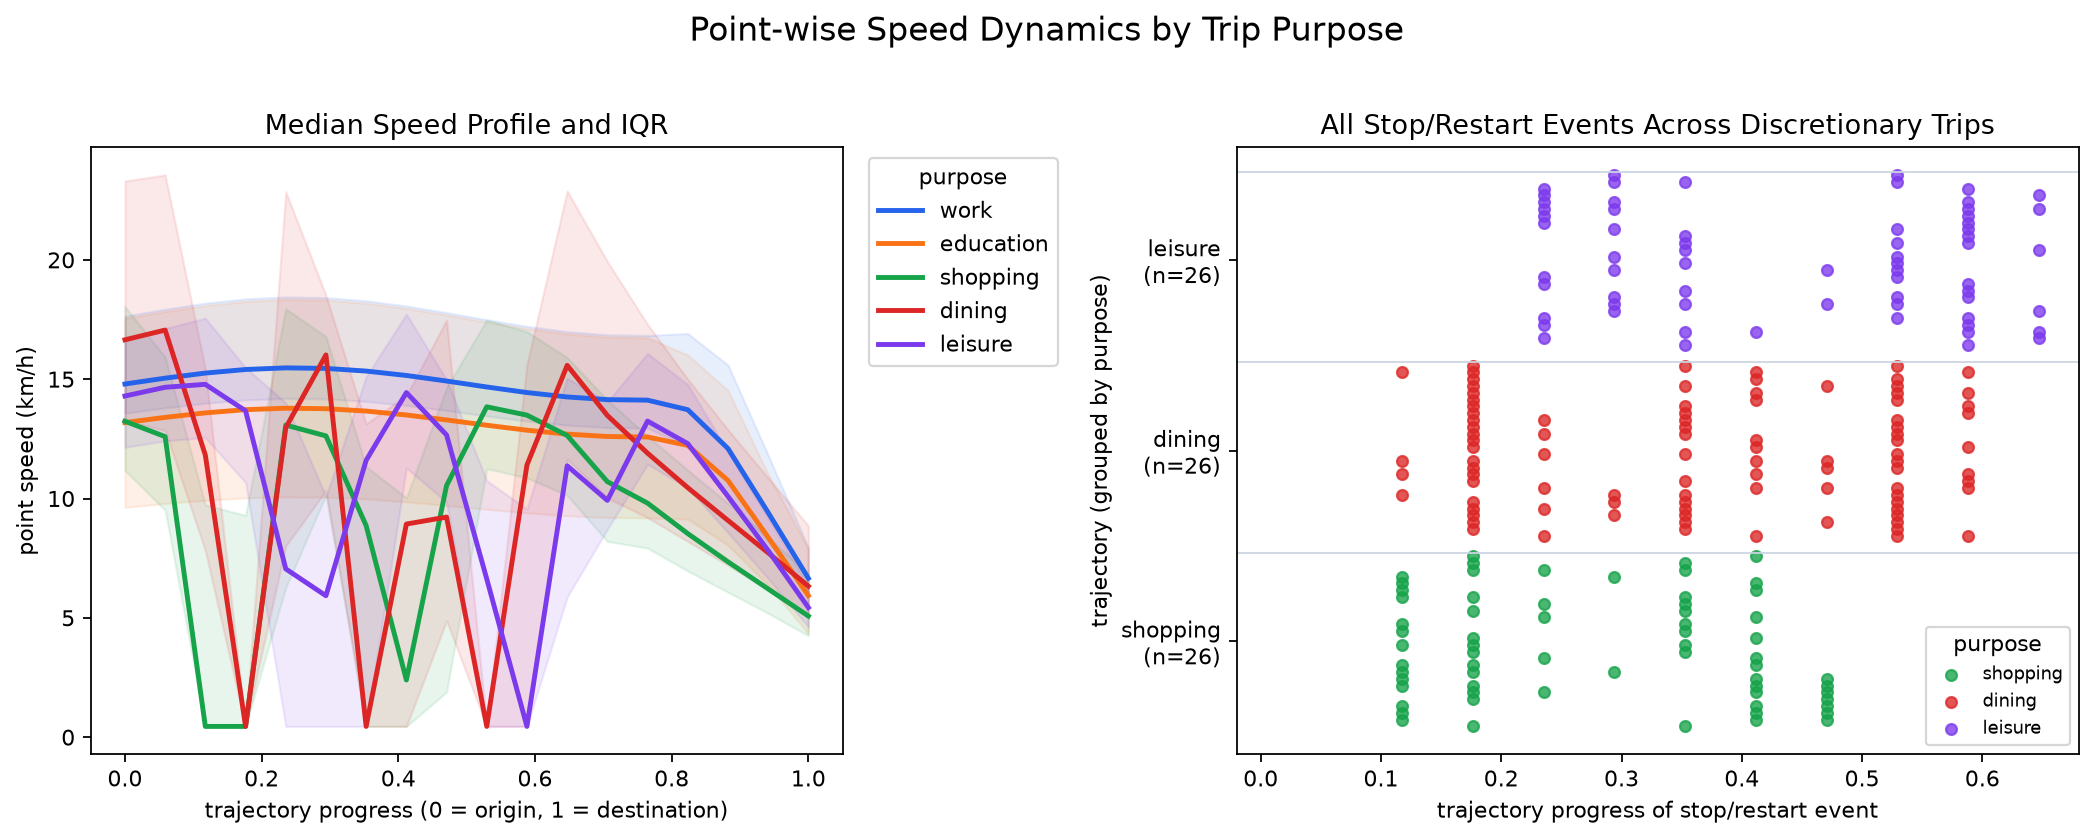

In [ ]:
user_df.groupby(['trajectory_id','purpose_group']).speed_kmh.agg(['std','min','max']); user_df.groupby('purpose_group').is_stop_or_restart.mean()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_dynamics_by_purpose.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_speed_dynamics",
  "insight": "Work- and education-related trajectories have more stable point-wise speed profiles, whereas shopping, dining, and leisure trajectories more often contain marked decelerations, stop/restart events, and renewed acceleration.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Point-wise Speed Dynamics by Purpose",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/speed_dynamics_by_purpose.png"
  },
  "question": "How do point-wise speed stability and stop/restart events differ across trip purposes?",
  "code": "user_df.groupby(['trajectory_id','purpose_group']).speed_kmh.agg(['std','min','max']); user_df.groupby('purpose_group').is_stop_or_restart.mean()",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "point_speed",
    "trajectory_id"
  ]
}

### **Question 2**: At what trajectory progress do Mixte-bound shopping and dining trips slow down relative to work trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

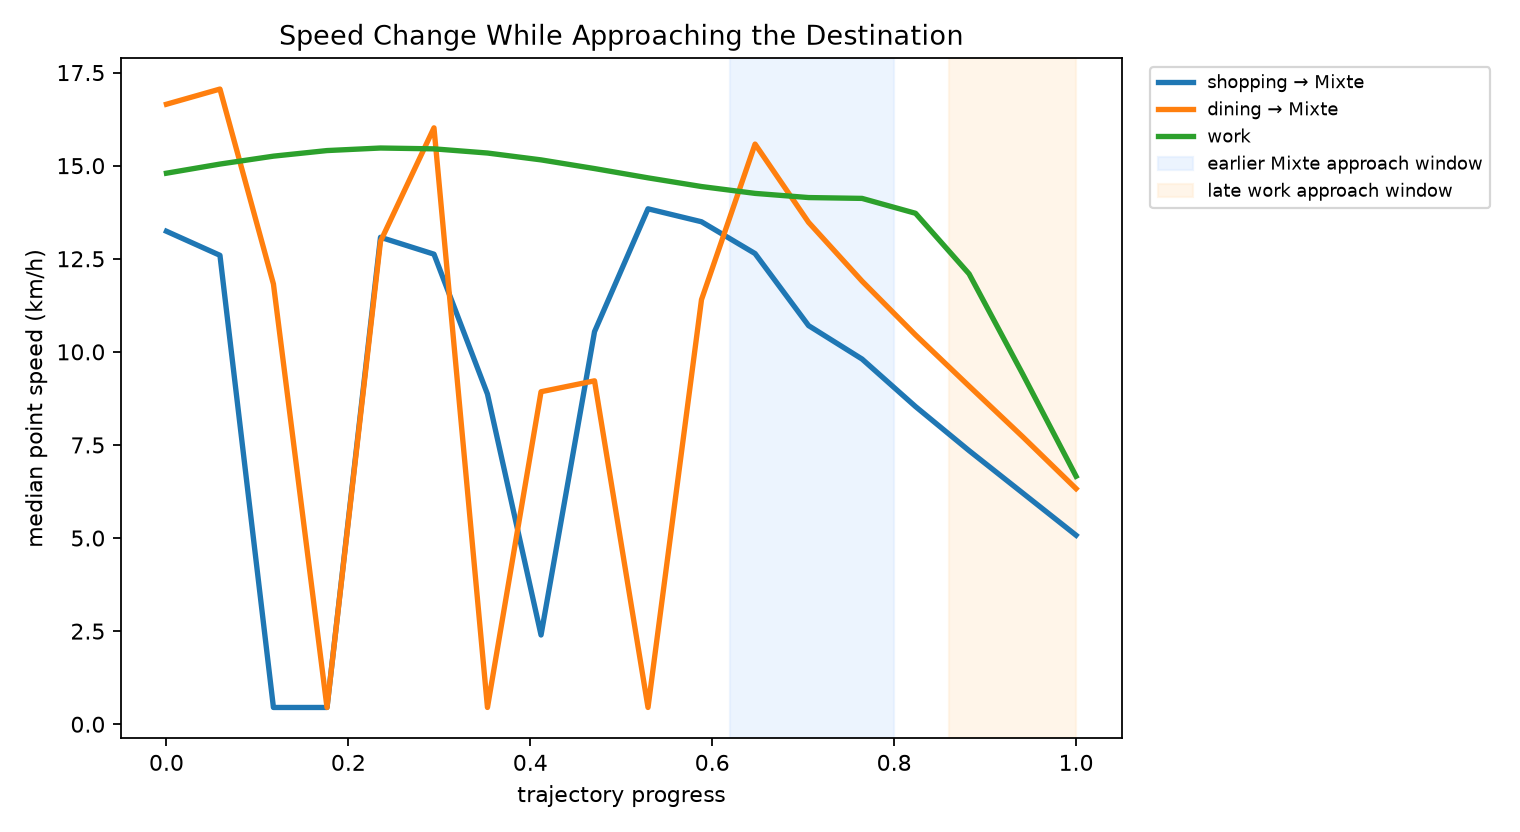

In [ ]:
df.groupby('purpose_group').first_approach_low_speed_progress.median(); user_df.groupby(['purpose_group','trajectory_progress']).speed_kmh.median()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/approach_speed_by_purpose.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_position_speed_approach",
  "insight": "Shopping and dining trajectories entering Mixte destinations begin a sustained low-speed approach earlier in their progress, whereas work trajectories typically decelerate only closer to the destination.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Spatial Position and Speed Near Destinations",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/approach_speed_by_purpose.png"
  },
  "question": "At what trajectory progress do Mixte-bound shopping and dining trips slow down relative to work trips?",
  "code": "df.groupby('purpose_group').first_approach_low_speed_progress.median(); user_df.groupby(['purpose_group','trajectory_progress']).speed_kmh.median()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "point_speed",
    "gps_position",
    "land_use_reference",
    "trajectory_id"
  ]
}

### **Question 3**: Within each transport mode, how do comparable long work, shopping, and leisure trips differ in speed variability and continuous stable segments?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

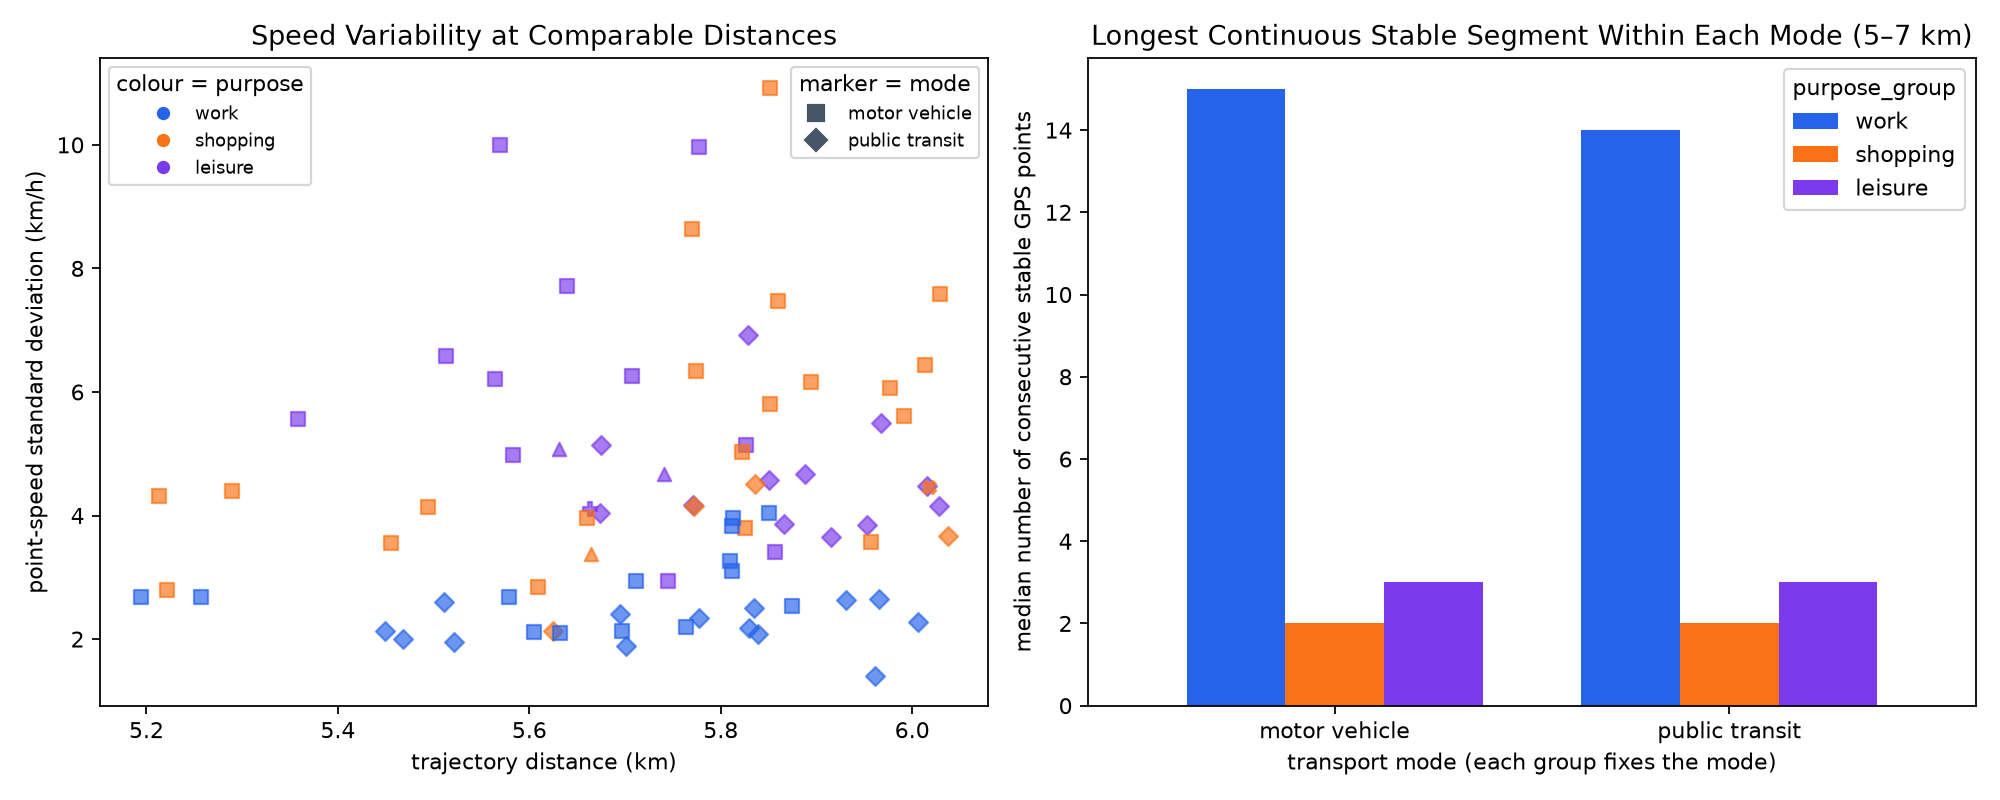

In [ ]:
df[df.distance_km.between(5,7) & df.mode_group.isin(['motor_vehicle','public_transit'])].groupby(['mode_group','purpose_group'])[['point_speed_std_kmh','longest_stable_run_points']].median()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/distance_mode_speed_structure.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "distance_mode_speed_structure",
  "insight": "Within both motor-vehicle and public-transit subsets of comparable longer-distance trajectories, work trips have longer continuous stable segments, while shopping or leisure trips show greater point-wise speed variability.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Distance, Mode, and Speed Structure",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/distance_mode_speed_structure.png"
  },
  "question": "Within each transport mode, how do comparable long work, shopping, and leisure trips differ in speed variability and continuous stable segments?",
  "code": "df[df.distance_km.between(5,7) & df.mode_group.isin(['motor_vehicle','public_transit'])].groupby(['mode_group','purpose_group'])[['point_speed_std_kmh','longest_stable_run_points']].median()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "point_speed",
    "transport_mode",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 3)

Work and education trajectories have comparatively stable speed profiles, whereas shopping, dining, and leisure trajectories more often include deceleration and stop/restart behaviour. Shopping and dining trips begin sustained low-speed approaches to Mixte destinations earlier; within comparable longer motor-vehicle and public-transit trips, work retains longer continuous stable segments than shopping or leisure.